# 01 — Exploration du dataset MS MARCO

Ce notebook génère les visualisations pour la section **"Présentation du problème et du dataset"** du rapport.
Toute la logique se trouve dans `src/`. Ce notebook ne contient que des appels.

In [1]:
from pathlib import Path
OUT_DIR = Path('../results/analysis/01_data_exploration')
OUT_DIR.mkdir(parents=True, exist_ok=True)

import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from src.data.dataset_factory import get_dataset
from src.retrieval.bm25.tokenizer import tokenize

# Palette de couleurs
COLORS = ['#e30513', '#ffc103', '#0099ff', '#515151', '#f7a941', '#51a27e', '#702e78', '#7b003d']

# Style matplotlib
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('seaborn-whitegrid')

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 1. Chargement des données

In [2]:
dataset = get_dataset("msmarco", data_dir="../data/")
corpus, queries_all, qrels = dataset.get_split(split="dev")

# Filtrage : uniquement les requêtes présentes dans les qrels dev
queries = {qid: q for qid, q in queries_all.items() if qid in qrels}

print(f"Corpus       : {len(corpus):,} passages")
print(f"Requêtes dev : {len(queries):,}")
print(f"Qrels dev    : {len(qrels):,} requêtes annotées")

Corpus       : 8,841,823 passages
Requêtes dev : 6,980
Qrels dev    : 6,980 requêtes annotées


## 2. Distribution des longueurs de requêtes (en tokens)

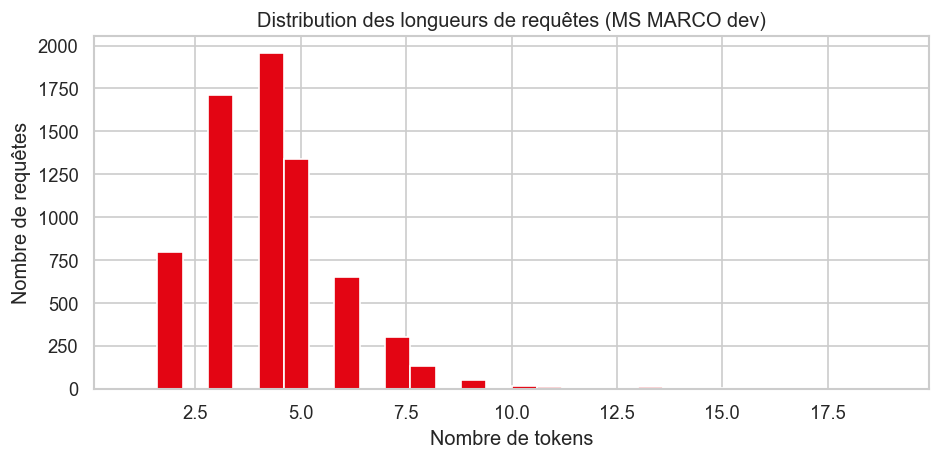

Longueur moyenne : 4.2 | Médiane : 4.0


In [3]:
query_lengths = [len(tokenize(q.text)) for q in queries.values()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(query_lengths, bins=30, color=COLORS[0], edgecolor="white")
ax.set_xlabel("Nombre de tokens")
ax.set_ylabel("Nombre de requêtes")
ax.set_title("Distribution des longueurs de requêtes (MS MARCO dev)")
plt.tight_layout()
plt.savefig(OUT_DIR / "query_length_distribution.png", dpi=150)
plt.show()
print(f"Longueur moyenne : {np.mean(query_lengths):.1f} | Médiane : {np.median(query_lengths):.1f}")

## 3. Distribution des longueurs de passages (en tokens)

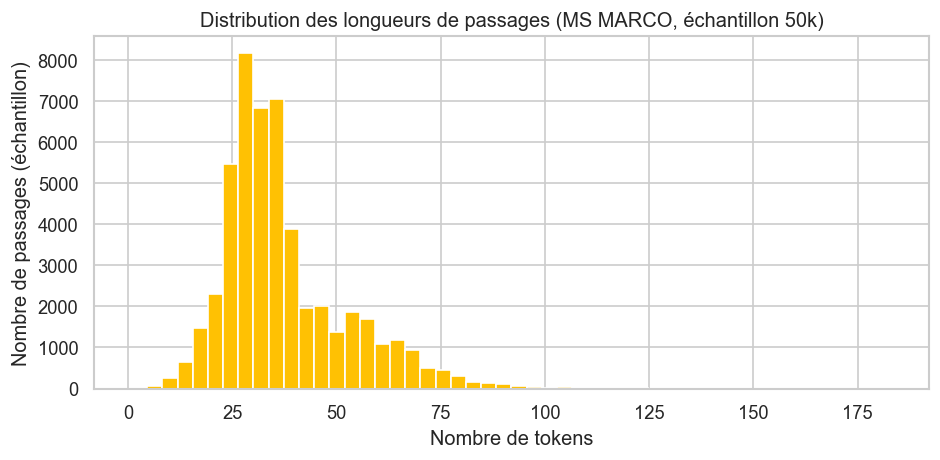

Longueur moyenne : 37.4 | Médiane : 33.0


In [4]:
# Échantillon de 50 000 passages pour la rapidité
import random
sample_pids = random.sample(list(corpus.keys()), min(50_000, len(corpus)))
passage_lengths = [len(tokenize(corpus[pid].text)) for pid in sample_pids]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(passage_lengths, bins=50, color=COLORS[1], edgecolor="white")
ax.set_xlabel("Nombre de tokens")
ax.set_ylabel("Nombre de passages (échantillon)")
ax.set_title("Distribution des longueurs de passages (MS MARCO, échantillon 50k)")
plt.tight_layout()
plt.savefig(OUT_DIR / "passage_length_distribution.png", dpi=150)
plt.show()
print(f"Longueur moyenne : {np.mean(passage_lengths):.1f} | Médiane : {np.median(passage_lengths):.1f}")

## 4. Distribution du nombre de passages pertinents par requête

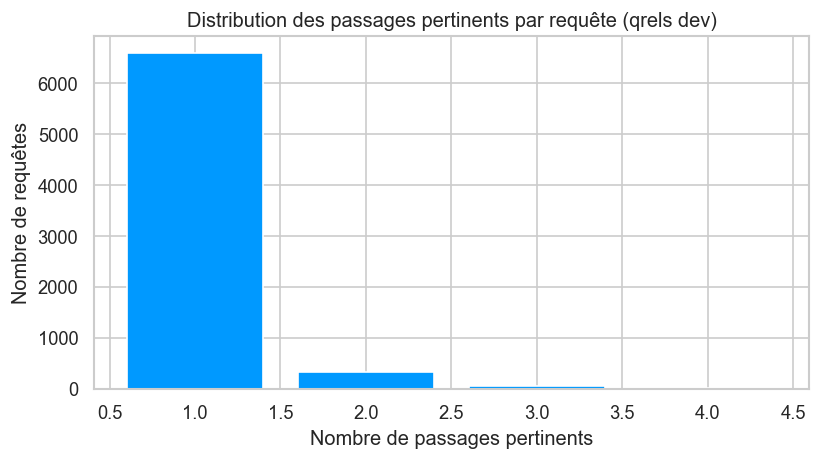

Moyenne : 1.07 | Requêtes avec 1 seul relevé : 6,590


In [5]:
n_relevant_per_query = [len(pids) for pids in qrels.values()]

fig, ax = plt.subplots(figsize=(7, 4))
from collections import Counter
counts = Counter(n_relevant_per_query)
ax.bar(counts.keys(), counts.values(), color=COLORS[2], edgecolor="white")
ax.set_xlabel("Nombre de passages pertinents")
ax.set_ylabel("Nombre de requêtes")
ax.set_title("Distribution des passages pertinents par requête (qrels dev)")
plt.tight_layout()
plt.savefig(OUT_DIR / "relevant_per_query_distribution.png", dpi=150)
plt.show()
print(f"Moyenne : {np.mean(n_relevant_per_query):.2f} | Requêtes avec 1 seul relevé : {counts.get(1, 0):,}")

## 5. Exemples annotés (requête + passage pertinent)

In [6]:
example_qids = list(qrels.keys())[:5]
for qid in example_qids:
    q = queries.get(qid)
    if q is None:
        continue
    relevant_pids = list(qrels[qid].keys())
    pid = relevant_pids[0]
    passage = corpus.get(pid)
    print(f"--- Requête [{qid}] ---")
    print(f"  Q : {q.text}")
    if passage:
        print(f"  P : {passage.text[:200]}...")
    print()

--- Requête [300674] ---
  Q : how many years did william bradford serve as governor of plymouth colony?
  P : http://en.wikipedia.org/wiki/William_Bradford_(Plymouth_Colony_governor) William Bradford (c.1590 â 1657) was an English Separatist leader in Leiden, Holland and in Plymouth Colony was a signatory t...

--- Requête [125705] ---
  Q : define preventive
  P : Adjective[edit] preventive â(comparative more preventive, superlative most preventive) 1  Preventing, hindering, or acting as an obstacle to.  Carried out to deter military aggression....

--- Requête [94798] ---
  Q : color overlay photoshop
  P : Photoshop: color overlay. In my sunlight touch up tutorial, I showed you how to add a hint of color to your photo while giving it an extra boost at the same time. However, sometimes a photo can benefi...

--- Requête [9083] ---
  Q : ____________________ is considered the father of modern medicine.
  P : TRUE. Hippocrates is considered the father of modern medicine because he

## 6. Statistiques générales

In [7]:
stats = {
    "Passages totaux dans le corpus": len(corpus),
    "Requêtes dev (annotées)": len(queries),
    "Paires (requête, passage pertinent) dev": sum(len(v) for v in qrels.values()),
    "Longueur moyenne requête (tokens)": round(float(np.mean(query_lengths)), 1),
    "Longueur moyenne passage (tokens, échantillon)": round(float(np.mean(passage_lengths)), 1),
}
for k, v in stats.items():
    print(f"{k:50s}: {v:,}" if isinstance(v, int) else f"{k:50s}: {v}")

Passages totaux dans le corpus                    : 8,841,823
Requêtes dev (annotées)                           : 6,980
Paires (requête, passage pertinent) dev           : 7,437
Longueur moyenne requête (tokens)                 : 4.2
Longueur moyenne passage (tokens, échantillon)    : 37.4
